# Disney historical wait times


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
c = pd.read_csv("data/calendar_enriched.csv", parse_dates=["date"])
r = pd.read_csv("data/ride_stats.csv")
print("Calendar shape", c.shape, "Ride statistics shape", r.shape)
print("Calendar range", c.date.min(), c.date.max())
display(c.dtypes.to_frame("dtype"), c.isna().sum().to_frame("missing"), r.isna().sum().to_frame("missing"))

Calendar shape (16682, 17) Ride statistics shape (2022, 8)
Calendar range 2015-01-01 00:00:00 2026-09-30 00:00:00


,dtype
park_id,int64
park_name,str
date,datetime64[us]
year,int64
month,int64
month_name,str
day_of_week,str
dow_number,int64
is_weekend,int64
crowd_level_pct,int64


,missing
park_id,0
park_name,0
date,0
year,0
month,0
month_name,0
day_of_week,0
dow_number,0
is_weekend,0
crowd_level_pct,0


,missing
park_id,0
park_name,0
year,0
ride_id,0
ride_name,0
is_archived,0
metric,0
minutes,0


In [2]:
display(c.crowd_level_pct.describe(), c.groupby("park_name").agg(dates=("date", "count"), mean_crowd=("crowd_level_pct","mean")))
print("High-crowd (>=80) share:", (c.crowd_level_pct>=80).mean())

count    16682.000000
mean        52.765076
std         27.736045
min          0.000000
25%         30.000000
50%         54.000000
75%         77.000000
max        100.000000
Name: crowd_level_pct, dtype: float64

,dates,mean_crowd
park_name,,
Animal Kingdom,4173,53.393961
Epcot,4167,51.346772
Hollywood Studios,4169,53.020149
Magic Kingdom,4173,53.297628


High-crowd (>=80) share: 0.2188586500419614


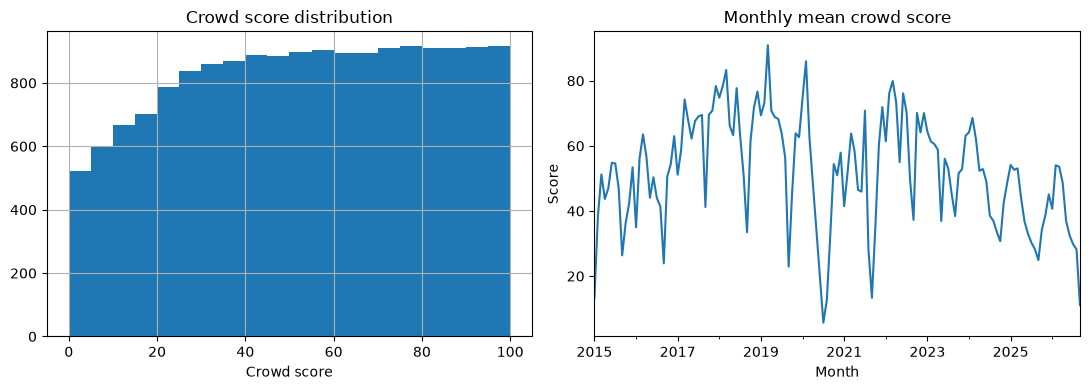

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
c.crowd_level_pct.hist(ax=axes[0], bins=20)
axes[0].set(title="Crowd score distribution", xlabel="Crowd score")
c.groupby(c.date.dt.to_period("M")).crowd_level_pct.mean().plot(ax=axes[1])
axes[1].set(title="Monthly mean crowd score", xlabel="Month", ylabel="Score")
plt.tight_layout(); plt.show()

In [4]:
yearly = r[(r.metric == "ride_avg_wait") & (r.year != "all_time") & (r.is_archived == 0)].copy()
display(yearly.groupby("park_name").minutes.describe())
print("Unique ride summary metrics:", r.metric.unique())
print("Duplicate park-date rows:", c.duplicated(["park_id", "date"]).sum())

,count,mean,std,min,25%,50%,75%,max
park_name,,,,,,,,
Animal Kingdom,80.0,36.425000,26.994502,5.0,19.0,31.0,41.25,142.0
Epcot,147.0,23.312925,18.292076,5.0,10.0,15.0,31.50,84.0
Hollywood Studios,110.0,34.990909,20.897520,5.0,16.0,32.0,49.00,109.0
Magic Kingdom,380.0,24.176316,16.060997,5.0,12.0,21.0,32.00,91.0


Unique ride summary metrics: <ArrowStringArray>
['ride_avg_wait', 'ride_max_wait']
Length: 2, dtype: str
Duplicate park-date rows: 0
